In [1]:
import sys
print(sys.executable)

c:\Users\jasmi\Documents\Fraud Detection Shadowing Project\.venv\Scripts\python.exe


In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("../data/fraudTrain.csv")

In [50]:
df.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [51]:
df.shape

(1296675, 23)

In [52]:
df.columns

Index(['Unnamed: 0', 'trans_date_trans_time', 'cc_num', 'merchant', 'category',
       'amt', 'first', 'last', 'gender', 'street', 'city', 'state', 'zip',
       'lat', 'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time',
       'merch_lat', 'merch_long', 'is_fraud'],
      dtype='str')

In [53]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 23 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Unnamed: 0             1296675 non-null  int64  
 1   trans_date_trans_time  1296675 non-null  str    
 2   cc_num                 1296675 non-null  int64  
 3   merchant               1296675 non-null  str    
 4   category               1296675 non-null  str    
 5   amt                    1296675 non-null  float64
 6   first                  1296675 non-null  str    
 7   last                   1296675 non-null  str    
 8   gender                 1296675 non-null  str    
 9   street                 1296675 non-null  str    
 10  city                   1296675 non-null  str    
 11  state                  1296675 non-null  str    
 12  zip                    1296675 non-null  int64  
 13  lat                    1296675 non-null  float64
 14  long                   129667

In [54]:
df["is_fraud"].value_counts()

is_fraud
0    1289169
1       7506
Name: count, dtype: int64

In [55]:
df["is_fraud"].value_counts(normalize=True) * 100

is_fraud
0    99.421135
1     0.578865
Name: proportion, dtype: float64

In [56]:
df["amt"].describe()

count    1.296675e+06
mean     7.035104e+01
std      1.603160e+02
min      1.000000e+00
25%      9.650000e+00
50%      4.752000e+01
75%      8.314000e+01
max      2.894890e+04
Name: amt, dtype: float64

In [57]:
df.groupby("is_fraud")["amt"].describe()

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,1289169.0,67.667110,154.007971,1.00,9.6100,47.280,82.540,28948.90
1,7506.0,531.320092,390.560070,1.06,245.6625,396.505,900.875,1376.04


In [58]:
import matplotlib.pyplot as plt

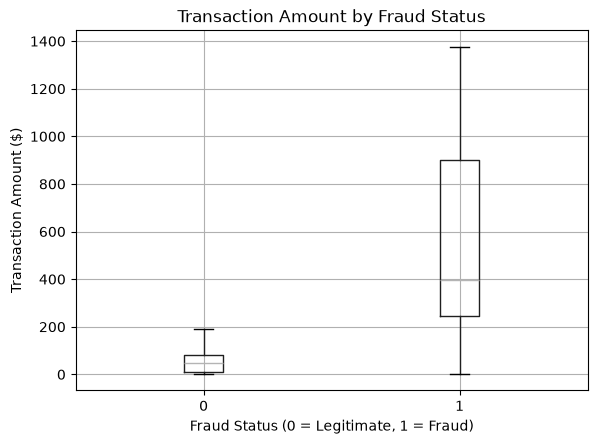

In [59]:
df.boxplot(column="amt", by="is_fraud", showfliers=False)

plt.title("Transaction Amount by Fraud Status")
plt.suptitle("")
plt.xlabel("Fraud Status (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction Amount ($)")
plt.show()

In [60]:
df["category"].value_counts()

category
gas_transport     131659
grocery_pos       123638
home              123115
shopping_pos      116672
kids_pets         113035
shopping_net       97543
entertainment      94014
food_dining        91461
personal_care      90758
health_fitness     85879
misc_pos           79655
misc_net           63287
grocery_net        45452
travel             40507
Name: count, dtype: int64

In [61]:
df[df["is_fraud"] == 1]["category"].value_counts()

category
grocery_pos       1743
shopping_net      1713
misc_net           915
shopping_pos       843
gas_transport      618
misc_pos           250
kids_pets          239
entertainment      233
personal_care      220
home               198
food_dining        151
grocery_net        134
health_fitness     133
travel             116
Name: count, dtype: int64

In [62]:
df.groupby("category")["is_fraud"].mean() * 100

category
entertainment     0.247835
food_dining       0.165098
gas_transport     0.469394
grocery_net       0.294817
grocery_pos       1.409761
health_fitness    0.154869
home              0.160825
kids_pets         0.211439
misc_net          1.445795
misc_pos          0.313853
personal_care     0.242403
shopping_net      1.756149
shopping_pos      0.722538
travel            0.286370
Name: is_fraud, dtype: float64

In [63]:
df["trans_date_trans_time"] = pd.to_datetime(df["trans_date_trans_time"])

In [64]:
df["trans_date_trans_time"].dtype

dtype('<M8[us]')

In [65]:
df["hour"] = df["trans_date_trans_time"].dt.hour

In [66]:
df[["trans_date_trans_time", "hour"]].head()

,trans_date_trans_time,hour
0,2019-01-01 00:00:18,0
1,2019-01-01 00:00:44,0
2,2019-01-01 00:00:51,0
3,2019-01-01 00:01:16,0
4,2019-01-01 00:03:06,0


In [67]:
df.groupby("hour")["is_fraud"].mean() * 100

hour
0     1.494047
1     1.534909
2     1.465210
3     1.423929
4     0.109882
5     0.142278
6     0.094563
7     0.132692
8     0.115281
9     0.111414
10    0.094628
11    0.099805
12    0.102671
13    0.122485
14    0.132542
15    0.120812
16    0.115632
17    0.119175
18    0.122633
19    0.123649
20    0.095241
21    0.112920
22    2.882864
23    2.837387
Name: is_fraud, dtype: float64

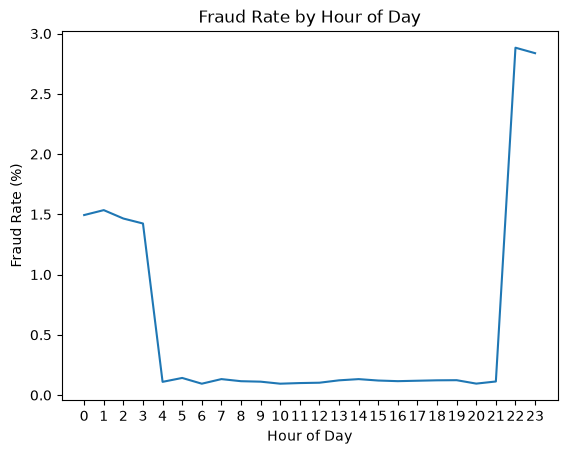

In [68]:
fraud_by_hour = df.groupby("hour")["is_fraud"].mean() * 100

fraud_by_hour.plot()

plt.title("Fraud Rate by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Fraud Rate (%)")
plt.xticks(range(0, 24))
plt.show()

In [69]:
import sys
print(sys.executable)

c:\Users\jasmi\Documents\Fraud Detection Shadowing Project\.venv\Scripts\python.exe


In [70]:
import pandas as pd
import matplotlib
import sys

print(sys.version)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)

3.13.1 (tags/v3.13.1:0671451, Dec  3 2024, 19:06:28) [MSC v.1942 64 bit (AMD64)]
pandas: 3.0.6
matplotlib: 3.11.2


In [71]:
df.head()

df.shape

df.columns

df.info()

df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 24 columns):
 #   Column                 Non-Null Count    Dtype         
---  ------                 --------------    -----         
 0   Unnamed: 0             1296675 non-null  int64         
 1   trans_date_trans_time  1296675 non-null  datetime64[us]
 2   cc_num                 1296675 non-null  int64         
 3   merchant               1296675 non-null  str           
 4   category               1296675 non-null  str           
 5   amt                    1296675 non-null  float64       
 6   first                  1296675 non-null  str           
 7   last                   1296675 non-null  str           
 8   gender                 1296675 non-null  str           
 9   street                 1296675 non-null  str           
 10  city                   1296675 non-null  str           
 11  state                  1296675 non-null  str           
 12  zip                    1296675 non-null

Unnamed: 0               0
trans_date_trans_time    0
cc_num                   0
merchant                 0
category                 0
amt                      0
first                    0
last                     0
gender                   0
street                   0
city                     0
state                    0
zip                      0
lat                      0
long                     0
city_pop                 0
job                      0
dob                      0
trans_num                0
unix_time                0
merch_lat                0
merch_long               0
is_fraud                 0
hour                     0
dtype: int64

In [72]:
df.describe()

,Unnamed: 0,trans_date_trans_time,cc_num,amt,zip,lat,long,city_pop,unix_time,merch_lat,merch_long,is_fraud,hour
count,1.296675e+06,1296675,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06
mean,6.483370e+05,2019-10-03 12:47:28.070213,4.171920e+17,7.035104e+01,4.880067e+04,3.853762e+01,-9.022634e+01,8.882444e+04,1.349244e+09,3.853734e+01,-9.022646e+01,5.788652e-03,1.280486e+01
min,0.000000e+00,2019-01-01 00:00:18,6.041621e+10,1.000000e+00,1.257000e+03,2.002710e+01,-1.656723e+02,2.300000e+01,1.325376e+09,1.902779e+01,-1.666712e+02,0.000000e+00,0.000000e+00
25%,3.241685e+05,2019-06-03 19:12:22.500000,1.800429e+14,9.650000e+00,2.623700e+04,3.462050e+01,-9.679800e+01,7.430000e+02,1.338751e+09,3.473357e+01,-9.689728e+01,0.000000e+00,7.000000e+00
50%,6.483370e+05,2019-10-03 07:35:47,3.521417e+15,4.752000e+01,4.817400e+04,3.935430e+01,-8.747690e+01,2.456000e+03,1.349250e+09,3.936568e+01,-8.743839e+01,0.000000e+00,1.400000e+01
75%,9.725055e+05,2020-01-28 15:02:55.500000,4.642255e+15,8.314000e+01,7.204200e+04,4.194040e+01,-8.015800e+01,2.032800e+04,1.359385e+09,4.195716e+01,-8.023680e+01,0.000000e+00,1.900000e+01
max,1.296674e+06,2020-06-21 12:13:37,4.992346e+18,2.894890e+04,9.978300e+04,6.669330e+01,-6.795030e+01,2.906700e+06,1.371817e+09,6.751027e+01,-6.695090e+01,1.000000e+00,2.300000e+01
std,3.743180e+05,NaN,1.308806e+18,1.603160e+02,2.689322e+04,5.075808e+00,1.375908e+01,3.019564e+05,1.284128e+07,5.109788e+00,1.377109e+01,7.586269e-02,6.817824e+00


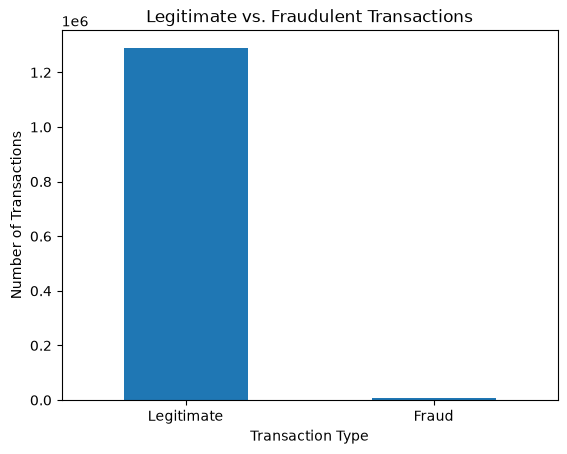

In [73]:
fraud_counts = df["is_fraud"].value_counts()

fraud_counts.plot(kind="bar")

plt.title("Legitimate vs. Fraudulent Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate", "Fraud"], rotation=0)

plt.show()

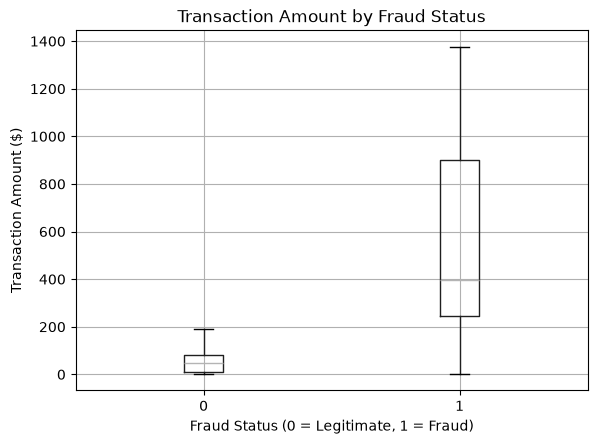

In [74]:
df.boxplot(column="amt", by="is_fraud", showfliers=False)

plt.title("Transaction Amount by Fraud Status")
plt.suptitle("")
plt.xlabel("Fraud Status (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction Amount ($)")
plt.show()

In [75]:
amount_bins = [0, 25, 50, 100, 250, 500, 1000, float("inf")]

amount_analysis = df.assign(
    amount_range=pd.cut(
        df["amt"],
        bins=amount_bins,
        include_lowest=True
    )
)

amount_summary = (
    amount_analysis
    .groupby("amount_range", observed=True)["is_fraud"]
    .agg(
        transaction_count="size",
        fraud_count="sum",
        fraud_rate="mean"
    )
)

amount_summary["fraud_rate_percent"] = amount_summary["fraud_rate"] * 100
amount_summary

,transaction_count,fraud_count,fraud_rate,fraud_rate_percent
amount_range,,,,
"(-0.001, 25.0]",463556,1552,0.003348,0.334803
"(25.0, 50.0]",208743,55,0.000263,0.026348
"(50.0, 100.0]",389483,45,0.000116,0.011554
"(100.0, 250.0]",196435,244,0.001242,0.124214
"(250.0, 500.0]",22827,1962,0.085951,8.595085
"(500.0, 1000.0]",11695,2699,0.230782,23.078239
"(1000.0, inf]",3936,949,0.241108,24.110772


In [76]:
df["trans_date_trans_time"] = pd.to_datetime(
    df["trans_date_trans_time"]
)

In [77]:
df["day_of_week"] = df["trans_date_trans_time"].dt.day_name()

In [78]:
df[["trans_date_trans_time", "day_of_week"]].head()

,trans_date_trans_time,day_of_week
0,2019-01-01 00:00:18,Tuesday
1,2019-01-01 00:00:44,Tuesday
2,2019-01-01 00:00:51,Tuesday
3,2019-01-01 00:01:16,Tuesday
4,2019-01-01 00:03:06,Tuesday


In [79]:
category_summary = (
    df.groupby("category")["is_fraud"]
    .agg(
        transaction_count="size",
        fraud_count="sum",
        fraud_rate="mean"
    )
)

category_summary["fraud_rate_percent"] = (
    category_summary["fraud_rate"] * 100
)

category_summary = category_summary.sort_values(
    "fraud_rate_percent",
    ascending=False
)

category_summary

,transaction_count,fraud_count,fraud_rate,fraud_rate_percent
category,,,,
shopping_net,97543,1713,0.017561,1.756149
misc_net,63287,915,0.014458,1.445795
grocery_pos,123638,1743,0.014098,1.409761
shopping_pos,116672,843,0.007225,0.722538
gas_transport,131659,618,0.004694,0.469394
misc_pos,79655,250,0.003139,0.313853
grocery_net,45452,134,0.002948,0.294817
travel,40507,116,0.002864,0.286370
entertainment,94014,233,0.002478,0.247835


In [80]:
df["category"].value_counts()

category
gas_transport     131659
grocery_pos       123638
home              123115
shopping_pos      116672
kids_pets         113035
shopping_net       97543
entertainment      94014
food_dining        91461
personal_care      90758
health_fitness     85879
misc_pos           79655
misc_net           63287
grocery_net        45452
travel             40507
Name: count, dtype: int64

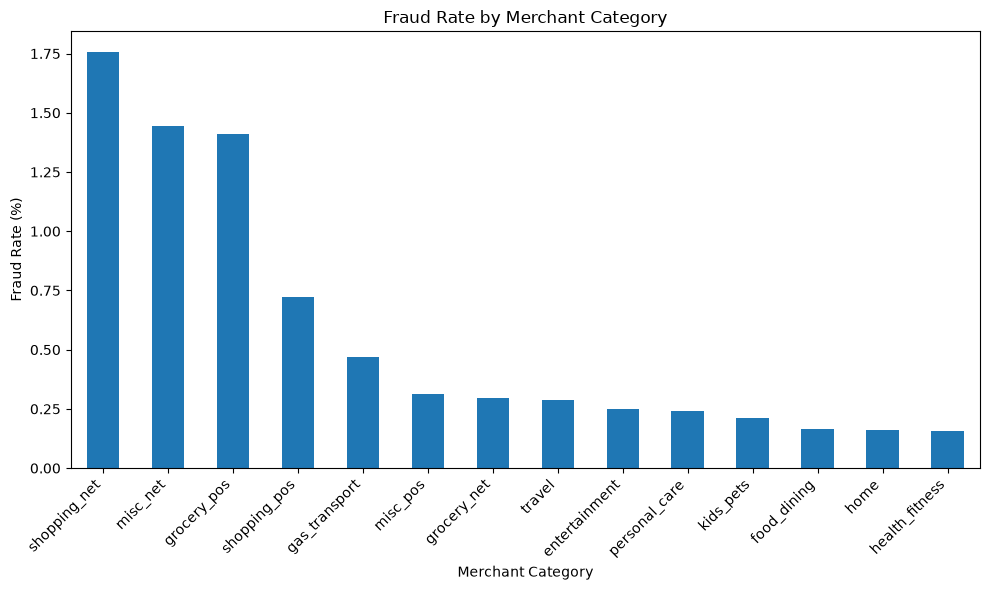

In [81]:
plt.figure(figsize=(10, 6))

category_summary["fraud_rate_percent"].plot(kind="bar")

plt.title("Fraud Rate by Merchant Category")
plt.xlabel("Merchant Category")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [82]:
df[["lat", "long", "merch_lat", "merch_long"]].head()

,lat,long,merch_lat,merch_long
0,36.0788,-81.1781,36.011293,-82.048315
1,48.8878,-118.2105,49.159047,-118.186462
2,42.1808,-112.2620,43.150704,-112.154481
3,46.2306,-112.1138,47.034331,-112.561071
4,38.4207,-79.4629,38.674999,-78.632459


In [83]:
import numpy as np

In [84]:
def haversine(lat1, lon1, lat2, lon2):
    R = 6371  # Earth's radius in kilometers

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return R * c

In [85]:
df["distance_km"] = haversine(
    df["lat"],
    df["long"],
    df["merch_lat"],
    df["merch_long"]
)

In [86]:
df[["lat", "long", "merch_lat", "merch_long", "distance_km"]].head()

,lat,long,merch_lat,merch_long,distance_km
0,36.0788,-81.1781,36.011293,-82.048315,78.597568
1,48.8878,-118.2105,49.159047,-118.186462,30.212176
2,42.1808,-112.2620,43.150704,-112.154481,108.206083
3,46.2306,-112.1138,47.034331,-112.561071,95.673231
4,38.4207,-79.4629,38.674999,-78.632459,77.556744


In [87]:
df.groupby("is_fraud")["distance_km"].describe()

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,1289169.0,76.113756,29.119051,0.022255,55.332701,78.233012,98.504498,152.117173
1,7506.0,76.268330,28.752602,0.738769,55.632890,77.931954,98.391090,144.522410


<Figure size 800x500 with 0 Axes>

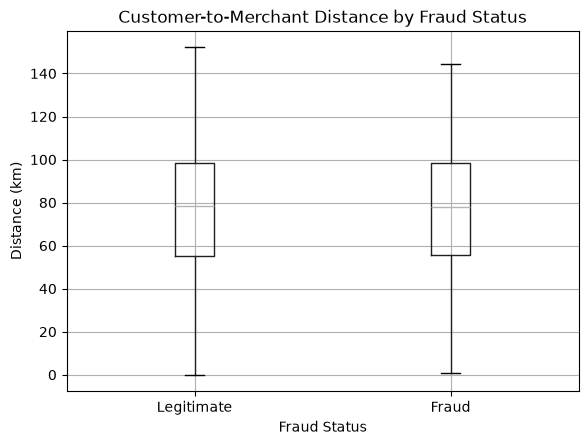

In [88]:
plt.figure(figsize=(8, 5))

df.boxplot(
    column="distance_km",
    by="is_fraud"
)

plt.title("Customer-to-Merchant Distance by Fraud Status")
plt.suptitle("")
plt.xlabel("Fraud Status")
plt.ylabel("Distance (km)")
plt.xticks([1, 2], ["Legitimate", "Fraud"])

plt.show()

In [89]:
df["dob"] = pd.to_datetime(df["dob"])

In [90]:
df["age"] = (
    (df["trans_date_trans_time"] - df["dob"]).dt.days / 365.25
).astype(int)

In [91]:
df[["dob", "trans_date_trans_time", "age"]].head()

,dob,trans_date_trans_time,age
0,1988-03-09,2019-01-01 00:00:18,30
1,1978-06-21,2019-01-01 00:00:44,40
2,1962-01-19,2019-01-01 00:00:51,56
3,1967-01-12,2019-01-01 00:01:16,51
4,1986-03-28,2019-01-01 00:03:06,32


In [92]:
df["age"].describe()

count    1.296675e+06
mean     4.549541e+01
std      1.739698e+01
min      1.300000e+01
25%      3.200000e+01
50%      4.300000e+01
75%      5.700000e+01
max      9.500000e+01
Name: age, dtype: float64

In [93]:
age_bins = [0, 20, 30, 40, 50, 60, 70, 80, float("inf")]
age_labels = [
    "<20",
    "20-29",
    "30-39",
    "40-49",
    "50-59",
    "60-69",
    "70-79",
    "80+"
]

df["age_group"] = pd.cut(
    df["age"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

In [94]:
age_summary = (
    df.groupby("age_group", observed=True)["is_fraud"]
    .agg(
        transaction_count="size",
        fraud_count="sum",
        fraud_rate="mean"
    )
)

age_summary["fraud_rate_percent"] = (
    age_summary["fraud_rate"] * 100
)

age_summary

,transaction_count,fraud_count,fraud_rate,fraud_rate_percent
age_group,,,,
<20,34841,223,0.006401,0.640051
20-29,209265,1223,0.005844,0.584426
30-39,291264,1286,0.004415,0.441524
40-49,304356,1385,0.004551,0.455059
50-59,184927,1388,0.007506,0.750566
60-69,136515,855,0.006263,0.626305
70-79,72863,625,0.008578,0.857774
80+,62644,521,0.008317,0.831684


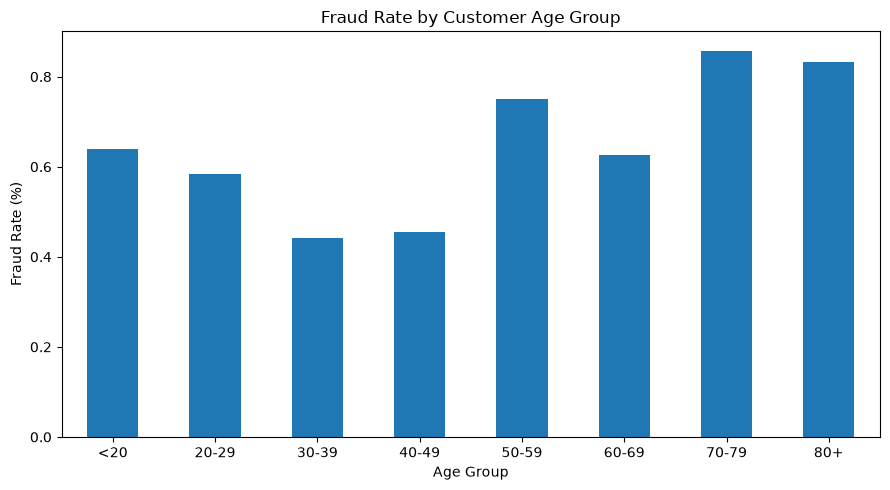

In [95]:
plt.figure(figsize=(9, 5))

age_summary["fraud_rate_percent"].plot(kind="bar")

plt.title("Fraud Rate by Customer Age Group")
plt.xlabel("Age Group")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [96]:
df[
    [
        "amt",
        "category",
        "hour",
        "day_of_week",
        "age",
        "distance_km",
        "is_fraud"
    ]
].head()

,amt,category,hour,day_of_week,age,distance_km,is_fraud
0,4.97,misc_net,0,Tuesday,30,78.597568,0
1,107.23,grocery_pos,0,Tuesday,40,30.212176,0
2,220.11,entertainment,0,Tuesday,56,108.206083,0
3,45.00,gas_transport,0,Tuesday,51,95.673231,0
4,41.96,misc_pos,0,Tuesday,32,77.556744,0


In [97]:
features = [
    "amt",
    "category",
    "hour",
    "day_of_week",
    "age",
    "distance_km"
]

X = df[features]
y = df["is_fraud"]

In [101]:
X.head()

,amt,category,hour,day_of_week,age,distance_km
0,4.97,misc_net,0,Tuesday,30,78.597568
1,107.23,grocery_pos,0,Tuesday,40,30.212176
2,220.11,entertainment,0,Tuesday,56,108.206083
3,45.00,gas_transport,0,Tuesday,51,95.673231
4,41.96,misc_pos,0,Tuesday,32,77.556744


In [100]:
y.head()

0    0
1    0
2    0
3    0
4    0
Name: is_fraud, dtype: int64